# Spotify Top 200 (2020-2021): What separates the hits?

Three steps on 1,556 songs from Spotify's weekly global Top 200 charts:

1. **PCA** on nine audio features to see which ones drive the variation between songs
2. **K-means** to group songs by danceability and energy
3. **Classification** (SVM, random forest, gradient boosting) to test whether audio features can tell a more popular chart song from a less popular one

Data: [Spotify Top 200 Charts (2020-2021)](https://www.kaggle.com/datasets/sashankpillai/spotify-top-200-charts-20202021) on Kaggle. Save the CSV as `data/spotify_dataset.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

DATA_PATH = "data/spotify_dataset.csv"
SEED = 42

## Data

Only the audio features are used as inputs. The other popularity measures (streams, weeks charted, chart position) are dropped so they can't stand in for the target. Some columns load as text, so they're converted to numbers and the 11 rows with missing values are dropped.

In [2]:
raw = pd.read_csv(DATA_PATH)

audio_features = ['Danceability', 'Energy', 'Loudness', 'Speechiness',
                  'Acousticness', 'Liveness', 'Tempo', 'Duration (ms)', 'Valence']

data = raw.copy()
data[audio_features + ['Popularity']] = data[audio_features + ['Popularity']].apply(pd.to_numeric, errors='coerce')
data = data.dropna(subset=audio_features + ['Popularity']).reset_index(drop=True)

print(f"{len(raw)} rows loaded, {len(data)} after dropping missing values")
data[audio_features + ['Popularity']].describe().round(3)

1556 rows loaded, 1545 after dropping missing values


,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence,Popularity
count,1545.000,1545.000,1545.000,1545.000,1545.000,1545.000,1545.000,1545.000,1545.000,1545.000
mean,0.690,0.633,-6.348,0.124,0.249,0.181,122.811,197940.817,0.515,70.089
std,0.142,0.162,2.509,0.110,0.250,0.144,29.591,47148.930,0.227,15.824
min,0.150,0.054,-25.166,0.023,0.000,0.020,46.718,30133.000,0.032,0.000
25%,0.599,0.532,-7.491,0.046,0.048,0.097,97.960,169266.000,0.343,65.000
50%,0.707,0.642,-5.990,0.076,0.161,0.124,122.012,193591.000,0.512,73.000
75%,0.796,0.752,-4.711,0.165,0.388,0.217,143.860,218902.000,0.691,80.000
max,0.980,0.970,1.509,0.884,0.994,0.962,205.272,588139.000,0.979,100.000


## 1. PCA on the audio features

Features are standardized so each one counts equally, then projected onto two components so the songs can be plotted in 2D.

In [3]:
X_audio = StandardScaler().fit_transform(data[audio_features])

pca = PCA(n_components=2)
Z = pca.fit_transform(X_audio)

for i, ratio in enumerate(pca.explained_variance_ratio_):
    print(f"Component {i+1} explains {ratio:.1%} of the variance")
print(f"Together: {pca.explained_variance_ratio_.sum():.1%}\n")

loadings = pd.DataFrame(pca.components_.T, index=audio_features, columns=['Component 1', 'Component 2'])
for col in loadings.columns:
    print(f"Features driving {col}:")
    print(loadings[col].reindex(loadings[col].abs().sort_values(ascending=False).index).round(5).to_string())
    print()

Component 1 explains 28.0% of the variance
Component 2 explains 14.8% of the variance
Together: 42.8%

Features driving Component 1:
Energy          -0.53365
Loudness        -0.52098
Acousticness     0.45414
Valence         -0.33713
Danceability    -0.31508
Speechiness     -0.10804
Tempo           -0.10555
Liveness        -0.04209
Duration (ms)   -0.00561

Features driving Component 2:
Danceability    -0.52315
Duration (ms)    0.50784
Speechiness     -0.45185
Valence         -0.28544
Energy           0.25963
Loudness         0.23379
Liveness         0.23335
Acousticness    -0.07678
Tempo            0.01891



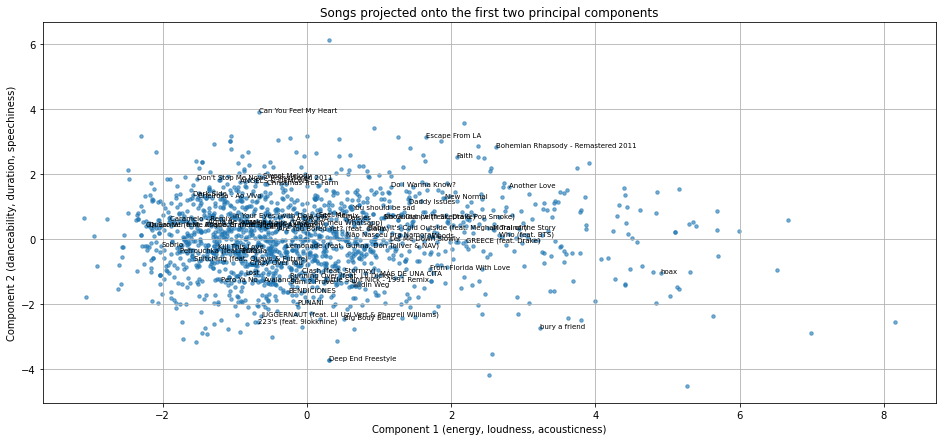

In [4]:
rng = np.random.default_rng(SEED)
labelled = rng.choice(len(data), size=60, replace=False)

plt.figure(figsize=(16, 7))
plt.scatter(Z[:, 0], Z[:, 1], s=12, alpha=0.6)
for i in labelled:
    plt.text(Z[i, 0], Z[i, 1], data.loc[i, 'Song Name'], fontsize=7)
plt.title("Songs projected onto the first two principal components")
plt.xlabel("Component 1 (energy, loudness, acousticness)")
plt.ylabel("Component 2 (danceability, duration, speechiness)")
plt.grid(True)
plt.show()

## 2. K-means on danceability and energy

Danceability and energy are the strongest drivers of the two components, so songs are clustered on those two features (standardized). The elbow plot is used to pick the number of clusters.

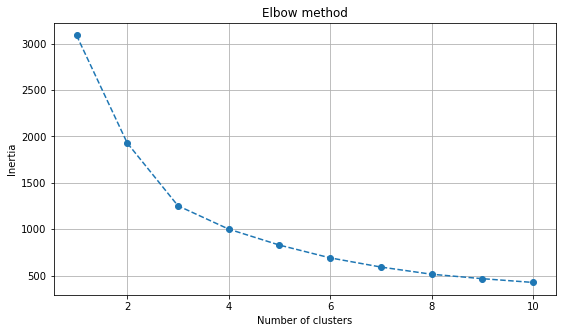

In [5]:
cluster_features = ['Danceability', 'Energy']
X_cluster = StandardScaler().fit_transform(data[cluster_features])

inertia = [KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_cluster).inertia_ for k in range(1, 11)]

plt.figure(figsize=(9, 5))
plt.plot(range(1, 11), inertia, marker='o', linestyle='--')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow method')
plt.grid(True)
plt.show()

In [6]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEED)
data['Cluster'] = kmeans.fit_predict(X_cluster)

summary = data.groupby('Cluster').agg(
    songs=('Song Name', 'size'),
    danceability=('Danceability', 'mean'),
    energy=('Energy', 'mean'),
    avg_popularity=('Popularity', 'mean'),
).round(3)
summary

,songs,danceability,energy,avg_popularity
Cluster,,,,
0,323,0.514,0.455,68.539
1,643,0.805,0.592,70.253
2,579,0.661,0.778,70.772


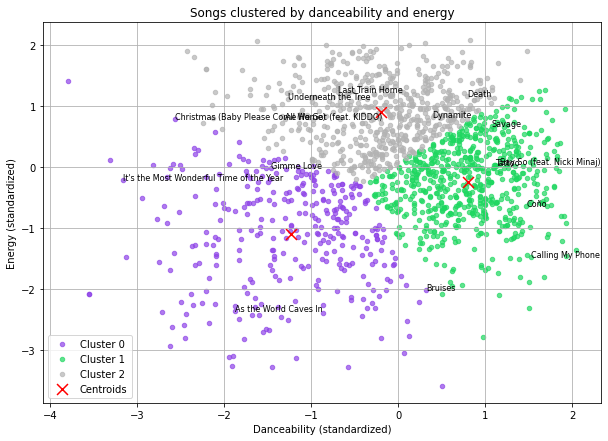

In [7]:
colors = ['#8E43E7', '#1ED760', '#B3B3B3']

plt.figure(figsize=(10, 7))
for label, color in zip(range(3), colors):
    members = np.where(data['Cluster'] == label)[0]
    plt.scatter(X_cluster[members, 0], X_cluster[members, 1], s=20, alpha=0.7, color=color, label=f'Cluster {label}')
    for i in rng.choice(members, size=5, replace=False):
        plt.text(X_cluster[i, 0], X_cluster[i, 1], data.loc[i, 'Song Name'], fontsize=8)

centroids = kmeans.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], marker='x', s=120, c='red', label='Centroids')
plt.title('Songs clustered by danceability and energy')
plt.xlabel('Danceability (standardized)')
plt.ylabel('Energy (standardized)')
plt.legend()
plt.grid(True)
plt.show()

## 3. Can audio features predict popularity?

Popularity (0-100) is turned into a yes/no label at a cutoff. Every song here already made the Top 200, so "popular" means more popular than other chart songs.

The models are compared with a baseline that always guesses the bigger class. With an uneven split, a model can score high accuracy while learning nothing, so the baseline is the number to beat.

- **SVM (RBF kernel)** on danceability and energy
- **Random forest** on the first two principal components of danceability, energy, loudness and duration
- **Gradient boosting** on those four features directly

Each model uses the same 80/20 train/test split. Scaling and PCA are fit inside a pipeline on the training set only, and the target is never one of the inputs.

In [8]:
model_features = ['Danceability', 'Energy', 'Loudness', 'Duration (ms)']

models = {
    'SVM (RBF)': (['Danceability', 'Energy'],
                  lambda: make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, gamma='auto'))),
    'Random forest (PCA)': (model_features,
                            lambda: make_pipeline(StandardScaler(), PCA(n_components=2),
                                                  RandomForestClassifier(n_estimators=100, random_state=SEED))),
    'Gradient boosting': (model_features,
                          lambda: GradientBoostingClassifier(random_state=SEED)),
}

rows = []
for cutoff in [70, 75, 85]:
    y = (data['Popularity'] >= cutoff).astype(int)
    idx_train, idx_test = train_test_split(data.index, test_size=0.2, random_state=SEED)
    y_train, y_test = y[idx_train], y[idx_test]

    majority = y_train.mode()[0]
    row = {'cutoff (popular if >=)': cutoff,
           'share popular': round(y.mean(), 3),
           'baseline (always guess majority)': round(accuracy_score(y_test, np.full(len(y_test), majority)), 3)}
    for name, (features, build) in models.items():
        model = build().fit(data.loc[idx_train, features], y_train)
        row[name] = round(accuracy_score(y_test, model.predict(data.loc[idx_test, features])), 3)
    rows.append(row)

results = pd.DataFrame(rows).set_index('cutoff (popular if >=)')
results

,share popular,baseline (always guess majority),SVM (RBF),Random forest (PCA),Gradient boosting
cutoff (popular if >=),,,,,
70,0.618,0.592,0.612,0.579,0.595
75,0.444,0.612,0.544,0.524,0.515
85,0.083,0.922,0.922,0.913,0.916


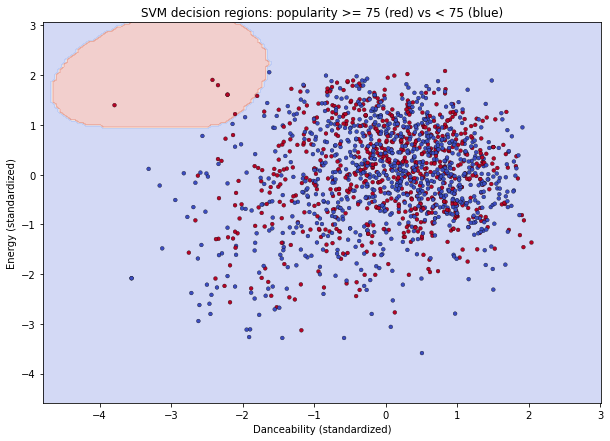

In [9]:
# Decision boundary for the SVM at a cutoff of 75 (close to the average popularity)
y = (data['Popularity'] >= 75).astype(int)
scaler = StandardScaler()
X2 = scaler.fit_transform(data[['Danceability', 'Energy']])
svm = SVC(kernel='rbf', C=1.0, gamma='auto').fit(X2, y)

xx, yy = np.meshgrid(np.arange(X2[:, 0].min() - 1, X2[:, 0].max() + 1, 0.05),
                     np.arange(X2[:, 1].min() - 1, X2[:, 1].max() + 1, 0.05))
grid = svm.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(10, 7))
plt.contourf(xx, yy, grid, alpha=0.25, cmap='coolwarm')
plt.scatter(X2[:, 0], X2[:, 1], c=y, cmap='coolwarm', s=15, edgecolor='k', linewidth=0.3)
plt.xlabel('Danceability (standardized)')
plt.ylabel('Energy (standardized)')
plt.title('SVM decision regions: popularity >= 75 (red) vs < 75 (blue)')
plt.show()

## Takeaways

- PCA separates songs mainly on intensity (energy, loudness, acousticness) and on a danceability-vs-length axis.
- K-means finds three loose groups in danceability and energy, but the groups have similar average popularity.
- No model beats the majority-class baseline by a meaningful margin at any cutoff. Among songs that already made the charts, these audio features don't predict how popular a song is. Artist reach, marketing and timing likely matter more, and they aren't in this dataset.